# Project Assignment 1

Time Series and Forecasting

In [1]:
## Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.dates as mdates

## Plot definitions
plt.style.use('ggplot')
pd.set_option('display.max_columns', 30)

In [2]:
## Load Data
project_dir = Path.cwd().parent
data_dir = project_dir / 'data'

olim_1989_2023 = (data_dir / 'olim-month-of-year-1989-2023.csv')
olim_2024      = (data_dir / "olim1_2024.xlsx")
olim_2025      = (data_dir / "olim1_2025.xlsx")

olim_1989_2023_raw = pd.read_csv(olim_1989_2023)
olim_2024_raw      = pd.read_excel(olim_2024)
olim_2025_raw      = pd.read_excel(olim_2025)

gpr = (data_dir / 'data_gpr_month.xls')
gpr_raw = pd.read_excel(gpr)



## 1. Description of the Selected Time Series and Their Expected Relationship

#### Main Series - New Olim by Month between 01.1989 - 12.2025 : 
A breakdown of the number of immigrants (Olim) arriving in Israel from January 1989 to December 2025, comprising 444 monthly observations. The series allows us to examine changes in immigration over time.

#### Exogenous Series - Israel's Geopolitical Risk Index (GPR)
The exogenous series is Israel's country-specific Geopolitical Risk Index (GPR), developed by Caldara and Iacoviello. The index is based on the monthly share of newspaper articles discussing geopolitical threats, tensions, and events that mention Israel or its major cities. Higher index values indicate greater reported geopolitical risk associated with Israel.


#### Expected Relationship : 
We hypothesize a negative relationship between geopolitical risk in Israel and the number of new immigrants arriving in the country. During periods of heightened security tensions or geopolitical instability, Israel may be perceived as a less attractive destination for immigration, potentially causing prospective immigrants to postpone their arrival. However, immigration decisions are complex and influenced by various factors. Therefore, changes in geopolitical risk may affect immigration with a lag of several months rather than immediately. Additionally, geopolitical events in immigrants' countries of origin may also influence immigration patterns.


## 2. Raw Data Sources

#### Main Series - New Olim by Month and Year - 
https://data.gov.il/he/datasets/ministry_of_immigrant_absorption/new-olim-by-month (1989-2023)

https://www.gov.il/he/pages/aliyah-data-2024

https://www.gov.il/he/pages/aliyah-data-2025

#### Exogenic Series - GPR specefic country :
https://www.matteoiacoviello.com/gpr_country.htm

In [3]:
olim_1989_2023_raw.head(n=10)

,year,month,olim
0,1989,1,1116
1,1989,2,1156
2,1989,3,1761
3,1989,4,1154
4,1989,5,1528
5,1989,6,1201
6,1989,7,1772
7,1989,8,2158
8,1989,9,2227
9,1989,10,2795


In [4]:
olim_2024_raw.head(n=10) # showing only 2024 as 2024 & 2025 are of the same structure

,לוח 1 : התפלגות עולים לפי תתי יבשות מוצא וחודש עליה ומגדר -מ 1/1/2024 עד 31/12/2024,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,מגדר,NaN,NaN,"סה""כ עולים",חודש עליה,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,ינואר,פברואר,מרץ,אפריל,מאי,יוני,יולי,אוגוסט,ספטמבר,אוקטובר,נובמבר,דצמבר
3,"סה""כ","סה""כ",NaN,32161,2425,2578,3314,2077,3436,3057,3324,3245,2838,1229,2627,2011
4,NaN,תת יבשת,מזרח אירופה,22833,1777,2075,2716,1619,2789,2402,2035,1455,1778,779,1998,1410
5,NaN,NaN,מערב אירופה,3562,203,183,197,188,185,252,590,686,409,194,276,199
6,NaN,NaN,צפון אמריקה,3723,206,182,162,168,225,261,495,934,479,166,204,241
7,NaN,NaN,מרכז דרום אמריקה,1017,133,57,100,53,175,63,114,84,103,20,72,43
8,NaN,NaN,ארצות ערב אפריקה,32,0,10,0,3,1,0,6,0,0,3,5,4
9,NaN,NaN,שאר אפריקה,402,43,33,88,19,25,33,30,34,19,22,22,34


In [5]:
gpr_raw.head(n=10)

,month,GPR,GPRT,GPRA,GPRH,GPRHT,GPRHA,SHARE_GPR,N10,SHARE_GPRH,N3H,GPRH_NOEW,GPR_NOEW,GPRH_AND,GPR_AND,...,GPRHC_PRT,GPRHC_RUS,GPRHC_SAU,GPRHC_SWE,GPRHC_THA,GPRHC_TUN,GPRHC_TUR,GPRHC_TWN,GPRHC_UKR,GPRHC_USA,GPRHC_VEN,GPRHC_VNM,GPRHC_ZAF,var_name,var_label
0,1900-01-01,NaN,NaN,NaN,87.927849,64.717491,110.453522,NaN,NaN,3.171932,7724,92.189819,NaN,116.949104,NaN,...,0.245987,0.258933,0.0,0.012947,0.077680,0.000000,0.038840,0.000000,0.0,2.718799,0.051787,0.012947,1.152253,month,Date (year/month)
1,1900-02-01,NaN,NaN,NaN,86.566490,71.936844,96.250488,NaN,NaN,3.122822,7173,91.032326,NaN,131.074982,NaN,...,0.139412,0.334588,0.0,0.000000,0.083647,0.000000,0.125471,0.000000,0.0,2.732469,0.027882,0.000000,1.143176,GPR,Recent GPR (Index: 1985:2019=100)
2,1900-03-01,NaN,NaN,NaN,72.140701,57.475853,84.499428,NaN,NaN,2.602422,7762,77.067757,NaN,112.938850,NaN,...,0.051533,0.386498,0.0,0.012883,0.115949,0.000000,0.180366,0.000000,0.0,2.151507,0.025767,0.000000,0.863180,GPRT,Recent GPR Threats (Index: 1985:2019=100)
3,1900-04-01,NaN,NaN,NaN,54.419449,37.326603,65.858208,NaN,NaN,1.963141,7488,61.985249,NaN,99.778038,NaN,...,0.080128,0.267094,0.0,0.000000,0.040064,0.000000,0.066774,0.000000,0.0,1.776175,0.000000,0.000000,0.641026,GPRA,Recent GPR Acts (Index: 1985:2019=100)
4,1900-05-01,NaN,NaN,NaN,64.405197,48.200008,74.373955,NaN,NaN,2.323370,7360,64.238335,NaN,105.352043,NaN,...,0.081522,0.176630,0.0,0.000000,0.163043,0.000000,0.081522,0.000000,0.0,1.970109,0.013587,0.000000,0.788043,GPRH,Historical GPR (Index: 1900:2019=100)
5,1900-06-01,NaN,NaN,NaN,83.610252,70.006577,93.977692,NaN,NaN,3.016178,7294,77.467339,NaN,124.273941,NaN,...,0.068549,0.945983,0.0,0.013710,0.082259,0.013710,0.109679,0.027420,0.0,2.728270,0.027420,0.041130,0.671785,GPRHT,Historical GPR Threats (Index: 1900:2019=100)
6,1900-07-01,NaN,NaN,NaN,108.571121,87.062378,125.709084,NaN,NaN,3.916622,7532,95.879486,NaN,134.726196,NaN,...,0.039830,1.035581,0.0,0.013277,0.252257,0.000000,0.146044,0.039830,0.0,3.544875,0.026553,0.026553,0.292087,GPRHA,Historical GPR Acts (Index: 1900:2019=100)
7,1900-08-01,NaN,NaN,NaN,108.502815,63.841644,149.760986,NaN,NaN,3.914158,7409,95.914795,NaN,126.370201,NaN,...,0.026994,1.106762,0.0,0.040491,0.242948,0.013497,0.080983,0.040491,0.0,3.549737,0.026994,0.013497,0.242948,SHARE_GPR,Percent of Recent GPR Articles
8,1900-09-01,NaN,NaN,NaN,62.813301,54.698414,67.581779,NaN,NaN,2.265943,7370,65.520256,NaN,108.190735,NaN,...,0.094980,0.786974,0.0,0.000000,0.135685,0.000000,0.040706,0.013569,0.0,2.008141,0.013569,0.000000,0.176391,N10,"Number of articles (10 recent newspapers, 1985-)"
9,1900-10-01,NaN,NaN,NaN,43.366932,31.717627,51.432850,NaN,NaN,1.564430,7287,46.683296,NaN,88.744675,NaN,...,0.013723,0.178400,0.0,0.013723,0.068615,0.000000,0.027446,0.000000,0.0,1.262522,0.000000,0.000000,0.205846,SHARE_GPRH,Percent of Historical GPR Articles


## 3. Description of the Processing Applied to the Time Series

In [6]:
# validation tests on raw data
start_year = 1989
end_year = 2025
end_month = 12
country="ISR"

gpr_selected = gpr_raw.loc[
    gpr_raw["month"].between(f"{start_year}-01-01", f"{end_year}-{end_month}-01")
]

# expected length and no missing, blank, or invalid values.
for name, values, expected_length in [
    ("Olim 1989–2023", olim_1989_2023_raw["olim"], 420),
    ("Olim 2024", olim_2024_raw.iloc[3, 4:], 12),
    ("Olim 2025", olim_2025_raw.iloc[3, 4:], 12),
    ("GPR 1989–2025", gpr_selected["GPRC_ISR"], 444),
]:
    assert len(values) == expected_length, f"{name}: incorrect number of months"
    assert np.isfinite(pd.to_numeric(values, errors="coerce")).all(), (
        f"{name}: missing, blank, or invalid values"
    )

# months must be consecutive, ordered, and without duplicates.
olim_dates = pd.to_datetime(
    olim_1989_2023_raw[["year", "month"]].assign(day=1)
)

## Olim_1989_2023 and GPR, Olim_2024 & Olim_2025 were verified manually
for name, dates, end in [
    ("Olim 1989–2023", olim_dates, "2023-12-01"),
    ("GPR 1989–2025", gpr_selected["month"], "2025-12-01"),
]:
    expected = pd.date_range("1989-01-01", end, freq="MS")
    assert pd.DatetimeIndex(dates).equals(expected), f"{name}: incorrect monthly dates"

In [7]:
### olim Processing
olim_until_2023_df = olim_1989_2023_raw[ olim_1989_2023_raw["year"] >= start_year ]["olim"] \
                        .reset_index(drop=True) # selecting start_year-2023 range

olim_2024_df = olim_2024_raw.iloc[3, 4:].reset_index(drop=True)

olim_2025_df = olim_2025_raw.iloc[3, 4:].reset_index(drop=True)

df_lst = [olim_until_2023_df, olim_2024_df, olim_2025_df]

olim = pd.concat(df_lst, axis=0) \
                    .reset_index(drop=True)

olim

0      1116
1      1156
2      1761
3      1154
4      1528
       ... 
439    2918
440    1989
441    1711
442    1722
443    1683
Length: 444, dtype: object

In [8]:
### gpr_ISR Processing
gpr_ISR = gpr_raw[ (gpr_raw['month'] >= f"{start_year}-01-01") & (gpr_raw['month'] <= f"{end_year}-{end_month}-01") ] \
    .filter(like = f'GPRC_{country}') \
    .reset_index(drop = True) 
       
gpr_ISR



,GPRC_ISR
0,0.587705
1,0.459546
2,0.431191
3,0.371386
4,0.411625
...,...
439,1.521739
440,1.384716
441,1.488616
442,0.584575


For the analysis, the common time period of January 1989 to December 2025 was selected for both time series, resulting in 444 monthly observations per series.

**Main Series** - Monthly Number of New Immigrants to Israel (Olim): Data from additional sources were combined with the original dataset to complete the years 2024-2025, while maintaining a monthly frequency.

**Exogenous Series** - Israel's Geopolitical Risk Index (GPR): The data were obtained from the Caldara and Iacoviello database, which contains geopolitical risk indices for different countries. The series corresponding to Israel (GPRC_ISR) was selected and filtered to match the chosen time period.

Before combining the series, we checked each dataset for missing, blank, non-numeric, or infinite values and verified its expected number of monthly observations. The historical immigration and GPR dates were also checked for complete monthly coverage, chronological order, and absence of duplicate dates.

## 4. Rationale for the Data Processing Choices

Both series were retained at their original monthly frequency, so no aggregation or frequency conversion was required. 

January 1989–December 2025 was selected to provide 444 consecutive months of common coverage. 

For 2024–2025, the overall monthly immigration totals were extracted, excluding annual totals and demographic breakdowns to avoid double-counting. 

Israel’s GPR series was selected and restricted to the same period. No missing values were found in the selected observations, so no imputation was necessary. 

Immigration counts were preserved as monthly totals because the quantity of interest is the number of arrivals per calendar month. 

Consequently, no adjustment for month length was applied, and the estimated seasonal pattern may partly reflect differences in the number of days per month. 

## 5. Final Data File (CSV)

In [9]:
assert len(gpr_ISR) == len(olim), "olim and gpr_ISR are not at the same length"

final_df = pd.concat([olim, gpr_ISR], axis=1)

final_df.columns = ["Olim Count", "GPR"]

final_df.index = pd.date_range(start=f'{start_year}-01-01', periods=len(final_df), freq='MS')

final_df

,Olim Count,GPR
1989-01-01,1116,0.587705
1989-02-01,1156,0.459546
1989-03-01,1761,0.431191
1989-04-01,1154,0.371386
1989-05-01,1528,0.411625
...,...,...
2025-08-01,2918,1.521739
2025-09-01,1989,1.384716
2025-10-01,1711,1.488616
2025-11-01,1722,0.584575


*Write your answer or notes here as requested, if applicable to this section. You may add more Markdown cells as needed.*

## 6. Initial Analysis of the Main Time Series and Its Decomposition into Components

In [10]:
def seasonal_decompose_wrapper(
    df, 
    model="additive", 
    period=12, 
    year_interval=None, 
    y_ticks=10,
    plot=True
):
    result = seasonal_decompose(
    df, model=model, period=period
    )

    if plot == False:
        return result

    fig = result.plot()
    fig.set_size_inches(15, 20)
    fig.suptitle(
        f"Seasonal Decomposition of Monthly Immigration to Israel - {model.upper()} model",
        fontsize=20, fontweight="bold", y=0.98
    )

    components = [result.observed, result.trend, result.seasonal, result.resid]
    labels = ["Data", "Trend", "Seasonal", "Residual"]
    y_labels = ["Olim Count", "Olim Count", "Seasonal Factor", "Residual Factor"]
    x_label = "Month [1M]"
    
    for ax, title, data, y_label in zip(fig.axes, labels, components, y_labels):
        # Titles and axis labels
        ax.set_title(title, fontweight="bold")
        ax.set_ylabel(y_label)
        ax.set_xlabel(x_label)
    
        # x-axis
        if year_interval:
            ax.xaxis.set_major_locator(mdates.YearLocator(year_interval))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.tick_params(axis="x", labelbottom=True)
    
        # y-axis
        ymin, ymax = data.min(), data.max()
        padding = (ymax - ymin) * 0.05 or 1
        ax.set_ylim(ymin - padding, ymax + padding)
        ax.set_yticks(np.linspace(ymin, ymax, y_ticks)) # Show y_ticks in y-axis, emphasizing min, max
        for tick in [ax.get_yticklabels()[0], ax.get_yticklabels()[-1]]: # ymin and ymax emphasized
            tick.set_fontweight("bold")
    
    return fig, result

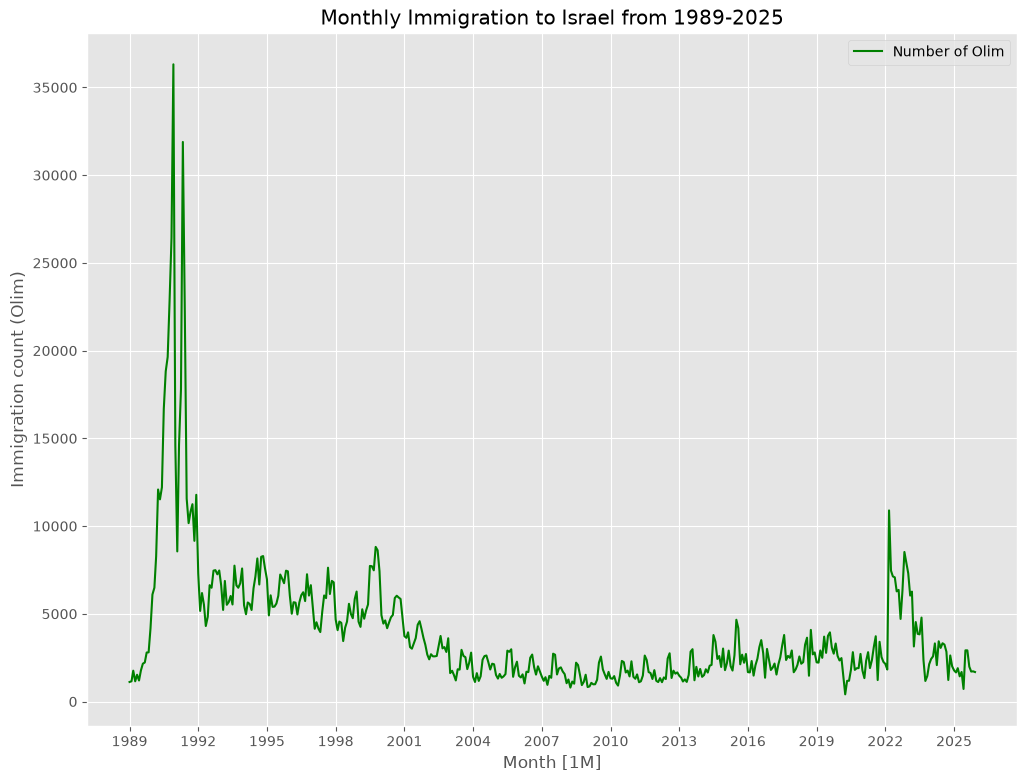

In [11]:
# Main Series analysis
fig, ax = plt.subplots()

sns.lineplot(
    data=final_df, 
    x=final_df.index, 
    y="Olim Count", 
    color="green", 
    label="Number of Olim"
)

ax.set(
    title="Monthly Immigration to Israel from 1989-2025",
    xlabel="Month [1M]",
    ylabel="Immigration count (Olim)",
)

ax.xaxis.set_major_locator(mdates.YearLocator(3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.tick_params(axis="x", labelbottom=True)

fig.set_size_inches(12, 9)
plt.show()

### Main Time Series Overview
The above plot present the number of immigrants (Olim) arriving in Israel from January 1989 to December 2025, comprising 444 monthly observations.
We can identify several intreseting trends and patterns:

* Two distinct major waves of immigration occured : around 1990 - 1992 & 2022-2023

* An overall decreasing number of immigraints to Israel since immigration peak in 1990-1991 over the years

* There are two time periods where immigration number would roughly stay consistent with no major spikes : 1992-2000 & 2003-2020

* Between 2000 and 2003 an ongoing negative trend in the baseline number of immigraints is observed

* 2024 onwards show similar behavior to immigration between 2003 and 2020

### Choice of decomposition model
Additive decomposition form :        Y_t = T_t + S_t + R_t 

Multiplicative decomposition form :  Y_t = T_t * S_t * R_t 

We considered both additive and multiplicative seasonal decomposition.
From the equations above, we can infer that decomposition models differ in both the seasonal effect and their modelling of flactuations behavior : 

#### Seasonal effect :
* The additive model assumes that seasonal effects contribute approximately constant absolute changes (each Janurary we see more 5000 immigrants than baseline trend)
* while the multiplicative model assumes that their magnitude is proportional to the series level (each Janurary we see 1.2X more immigrant than baseline trend)

#### Flactuations Behavior :
* The additive model assumes that magnitude of the seasonal fluctuations, does not vary with the level of the time series
* While the multiplicative model assumes that their magnitude is proportional to the series level

Or in simple terms, whether fluctuations around the trend won't vary in magnitude (additive model) or would vary proportionaly to the trend (multiplicative model).


From a domain perspective, a multiplicative seasonal effect is plausible for immigration: seasonal factors may influence the proportion of immigrants arriving in a given month rather than contributing a constant number of immigrants.

We would examine this hypothesis by analyzing the relationship between the trend and the observed deviation at that time.
If the deviation spread remains approximately constant regardless of the trend values, an additive model is plausible.
But if the spread increases as the trend increases, this suggests trend magnitude dependent fluctuations, making multiplicative model more plausible.

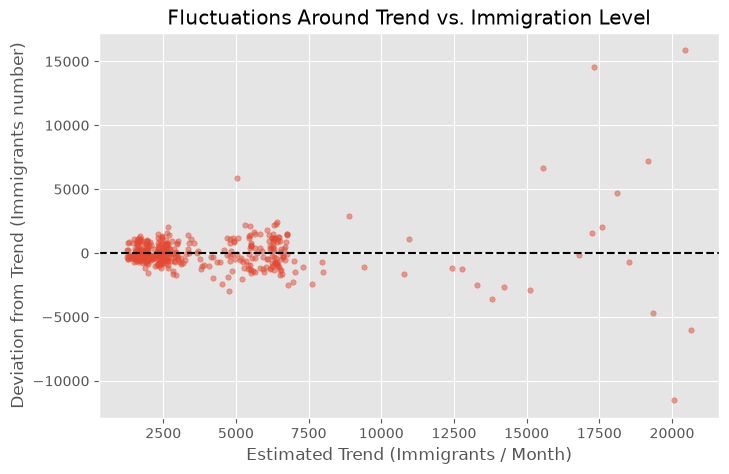

In [12]:
# Deviations vs Trend behavior plot
monthly=12

result = seasonal_decompose_wrapper(
    final_df["Olim Count"], 
    plot=False
)

deviation = result.observed - result.trend

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(result.trend, deviation, alpha=0.5, s=15)
ax.axhline(0, color="black", linestyle="--")

ax.set(
    title="Fluctuations Around Trend vs. Immigration Level",
    xlabel="Estimated Trend (Immigrants / Month)",
    ylabel="Deviation from Trend (Immigrants number)"
)

plt.show()

The scatter plot shows a **fan-shaped spreading**, with larger fluctuations as the immigration trend increases. This suggests level-dependent variability, supporting a multiplicative decomposition as explained in the previous cell.

***Therefore, we selected multiplicative decomposition as a reasonable initial representation.***


**However**, some of the observed variability reflects exceptional immigration waves rather than seasonality, so this choice should not be interpreted as evidence that seasonal effects are strictly proportional to the series level as expected in multiplicative model. 

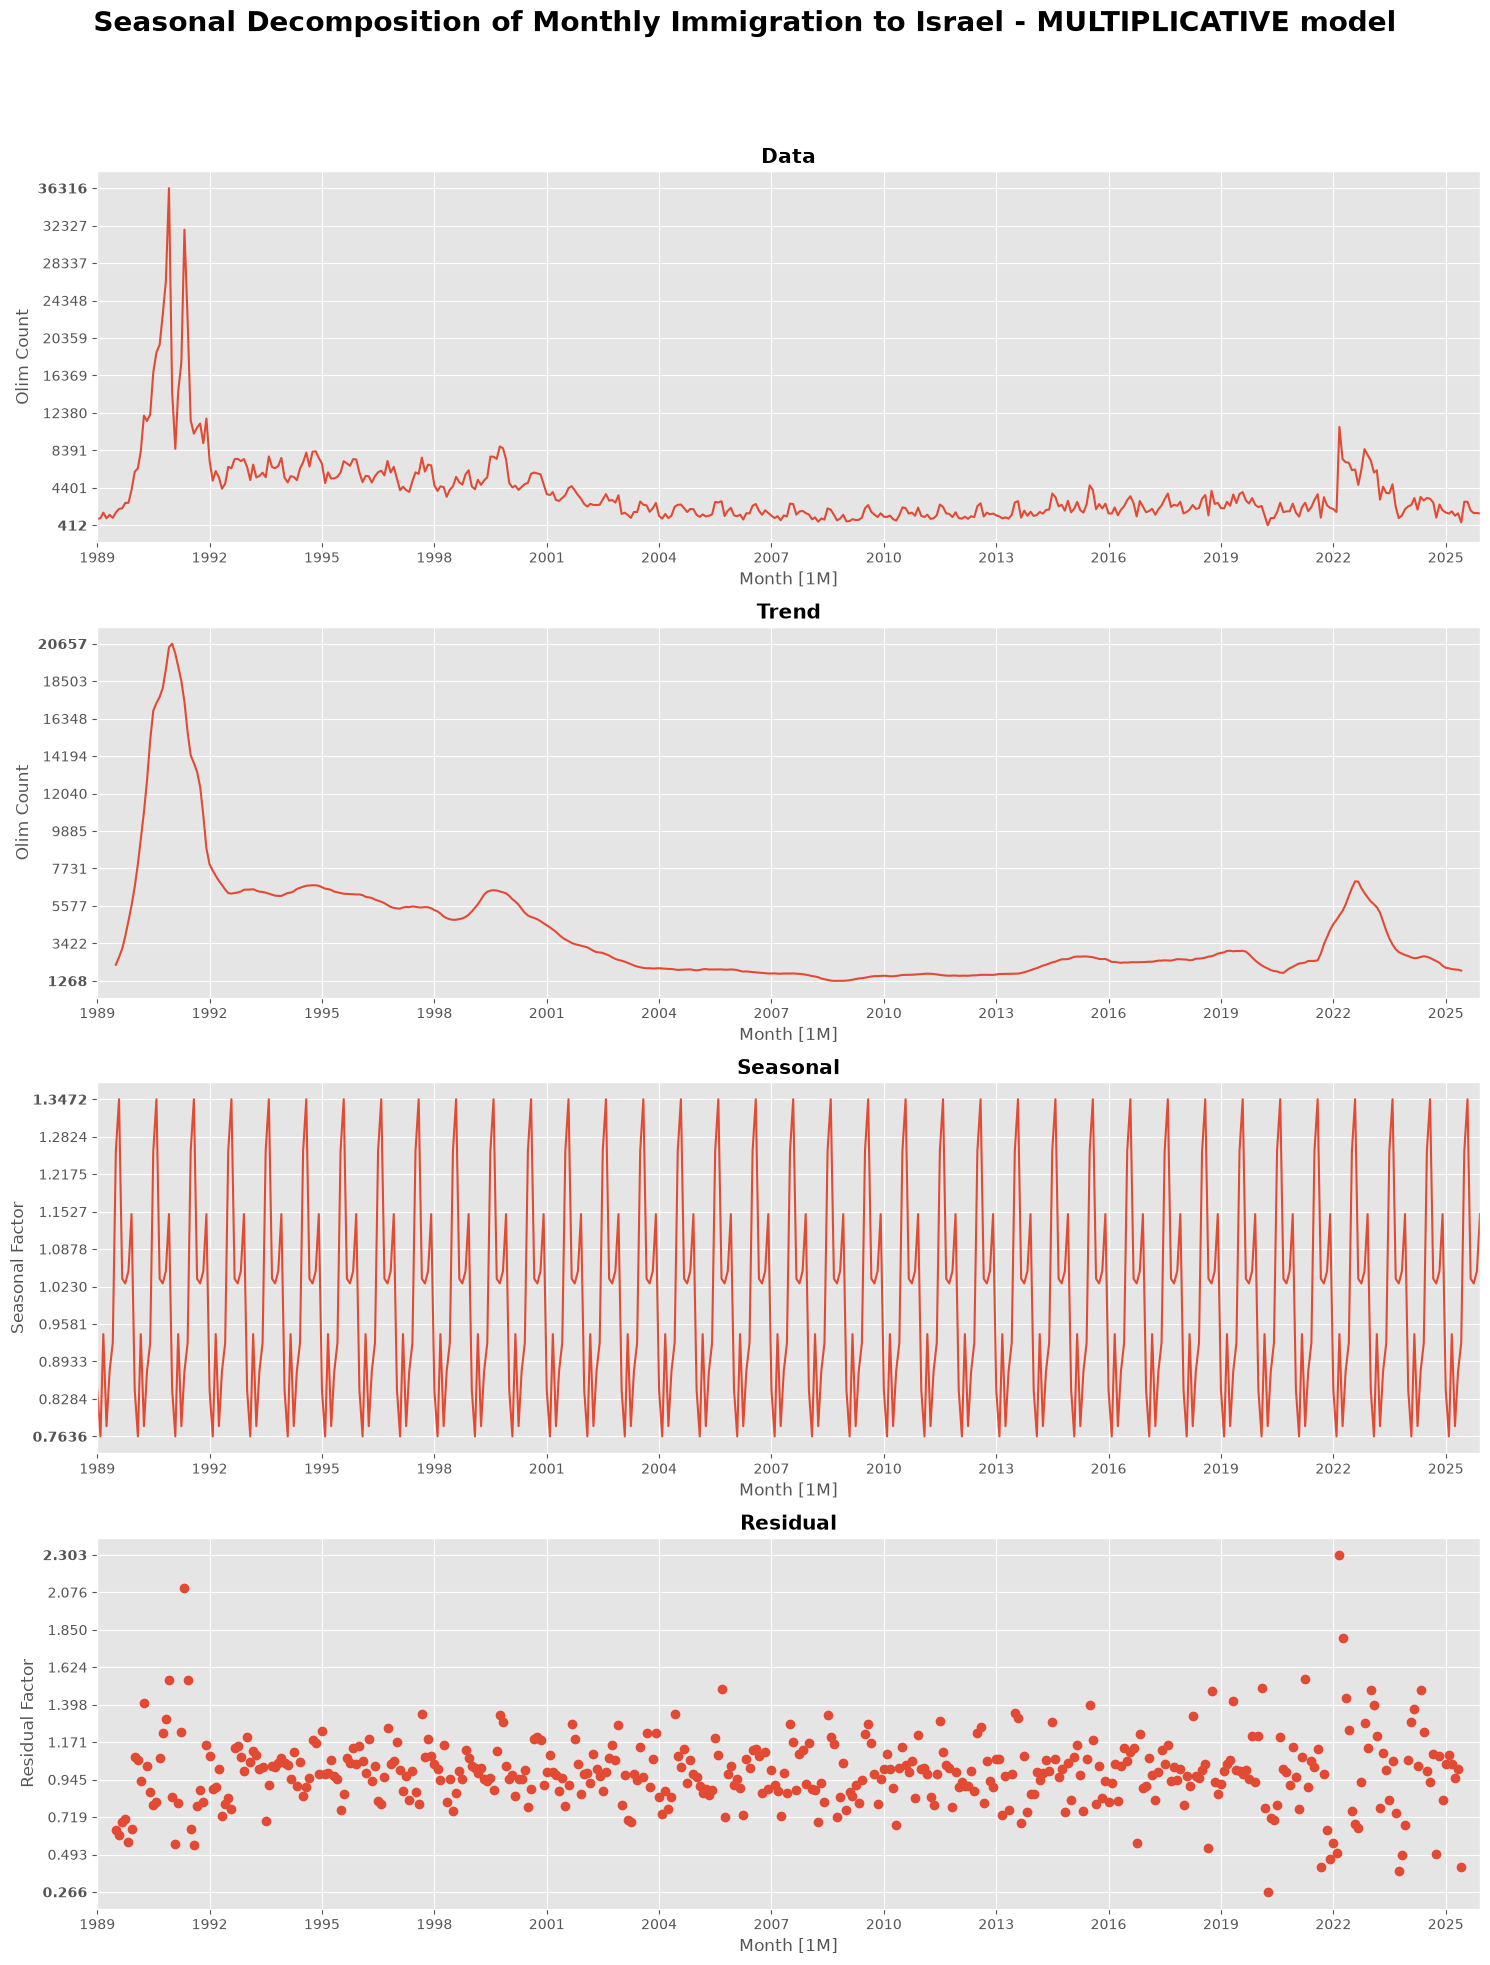

In [13]:
# Multiplicative  model decomposition of "Olim Count" TS
monthly=12
model="multiplicative"
year_interval = 3

fig, result = seasonal_decompose_wrapper(final_df["Olim Count"], model=model, period=monthly, year_interval=year_interval)
fig.tight_layout(rect=[0, 0, 1, 0.94])

resid_mean, resid_median, resid_variance   = result.resid.mean(), result.resid.median(), result.resid.var()

#### Seasonal Decomposition Analysis

##### Trend 
Analysis of the trend give out similar observations to our main series analysis :
There are two distinct major waves of immigration : around 1990 - 1992 & 2022-2023, 
An overall decreasing number of immigraints to Israel since immigration peak, 
There are two stable "time regimes" where immigration is consistant with minor changes 
and a noticable decreasing trend between those two "time regimes".

##### Seasonal
The seasonal component reveals recurring within-year fluctuations as percentages of the main trend.
For example, Janurary have a negative seasonal effect - approximately ~15% below trend.
We can identify a general pattern in the monthly effect on immigration (see "Monthly Effect Over a Year" plot in later section) :

Janurary to June show negative impact on immigration with Feburary having the biggest effect - approximately ~23% below trend. 

July to December show positive impact on immigration with Augut having the biggest effect - approximately 34~ above trend.  

##### Residual
The residual (also known as remainder) component captures the variation not explained by the estimated trend and seasonal components.
In a multiplicative decomposition, we generally expect the remainder to fluctuate around 1, without systematic patterns or strong changes in variability. Significant autocorrelation may indicate remaining temporal structure that the decomposition does not capture.
The last attribute would be more important once we start analyzing autoregressive forecasting models on the data.

For the most part, the remainder exhibits the desired behavior except several pronounced deviations, particularly during major immigration waves (1990–1992 and 2022–2023), suggesting that exceptional changes in immigration are not fully captured by the trend and seasonal components.

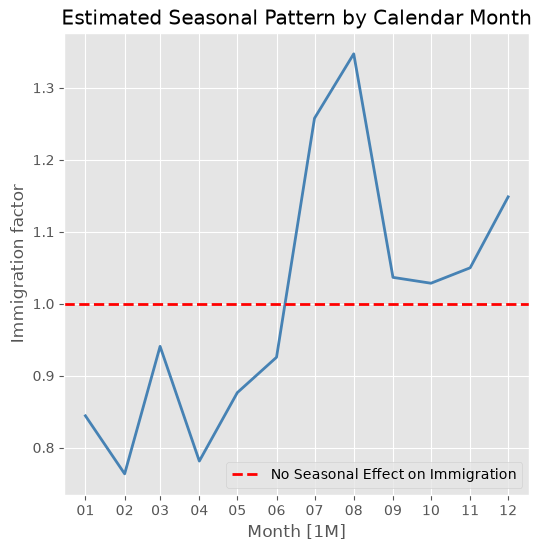

In [14]:
# Monthly Effect Over a Year on Immigration
yearly_seasonal = result.seasonal.head(n=12)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(yearly_seasonal.index, yearly_seasonal, linewidth=2, color="steelblue")

ax.set(
    title="Estimated Seasonal Pattern by Calendar Month",
    xlabel="Month [1M]",
    ylabel="Immigration factor",
)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.tick_params(axis="x", labelbottom=True)

ax.axhline(y=1, color="red", linestyle="--", linewidth=2, label="No Seasonal Effect on Immigration")
ax.legend()

plt.show()